Abrindo, tratando e verificando dados.

In [62]:

import matplotlib.pyplot as plt
import pandas as pd

url = "vendas.csv"

df_url = pd.read_csv(url, sep=';')
df_url['cidade_cliente'] = df_url['cidade_cliente'].fillna('Não Informada')
df_tratado = df_url.drop_duplicates().copy()
df_tratado['quantidade'] = df_tratado['quantidade'].abs()
nomes_vendedores = df_url.groupby("nome_vendedor").size()
print (nomes_vendedores)


nome_vendedor
Ana Silva         3348
Bruno Costa       3236
Carlos Eduardo    3479
Diana Souza       3298
Eduardo Lima      3237
Fernanda Alves    3418
Gabriel Gomes     3328
Helena Rocha      3214
Igor Santos       3225
Julia Martins     3484
Kauan Vieira      3419
Larissa Mendes    3304
Marcos Paulo      3420
Natália Pires     3203
Otávio Borges     3387
dtype: int64


NameError: name 'faturamento_total_bruto' is not defined

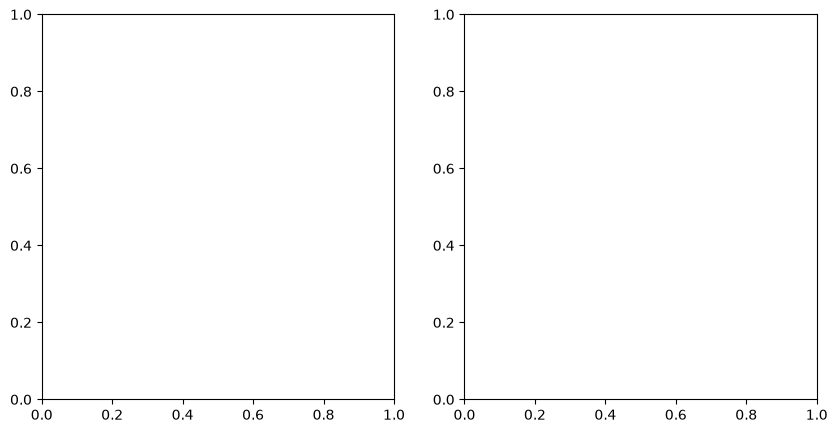

In [59]:
fig, axs = plt.subplots(1,2, figsize=(10,5))

df_vendas_bruto = df_url[df_url['status_venda'] == 'Concluído']

categorias = ['Faturamento Bruto', 'Descontos', 'Faturamento Líquido']
valores_milhoes = [
    faturamento_total_bruto / 1e6,
    total_descontos / 1e6,
    faturamento_total_liquido / 1e6
]


In [50]:
df_url['faturamento_bruto'] = df_url['quantidade'] * df_url['preco_unitario']

print (df_url)

       id_item_venda  id_pedido           data_venda             nome_produto  \
0                  1      10000  2021-08-17 00:00:00      Mouse Gamer 10k DPI   
1                  2      10000  2021-08-17 00:00:00     Smartphone Premium X   
2                  3      10001  2021-02-24 00:00:00          Smart TV 55" 4K   
3                  4      10002  2022-11-28 00:00:00           Monitor 27" 4K   
4                  5      10002  2022-11-28 00:00:00     Teclado Mecânico RGB   
...              ...        ...                  ...                      ...   
49995          23494      23439  2021-10-11 00:00:00      Monitor 24" Full HD   
49996          15790      19051  2021-05-18 00:00:00      Mouse Gamer 10k DPI   
49997          35780      30464  2022-09-27 00:00:00            Cabo USB-C 2m   
49998          11981      16863  2022-07-20 00:00:00          Smart TV 55" 4K   
49999          44906      35742  2021-02-07 00:00:00  Carregador Super Rápido   

      categoria_produto  qu

Calculei o faturamento bruto por item (quantidade X preço) e o líquido por categoria para entender a situação atual das vendas.

------------- RESUMO DE FATURAMENTO (VENDAS CONCLUÍDAS) -------------
Faturamento Total Bruto:   R$ 117,896,870.60
Total de Descontos:        R$ 7,344,725.79 (6.23%)
Faturamento Total Líquido: R$ 110,552,144.81


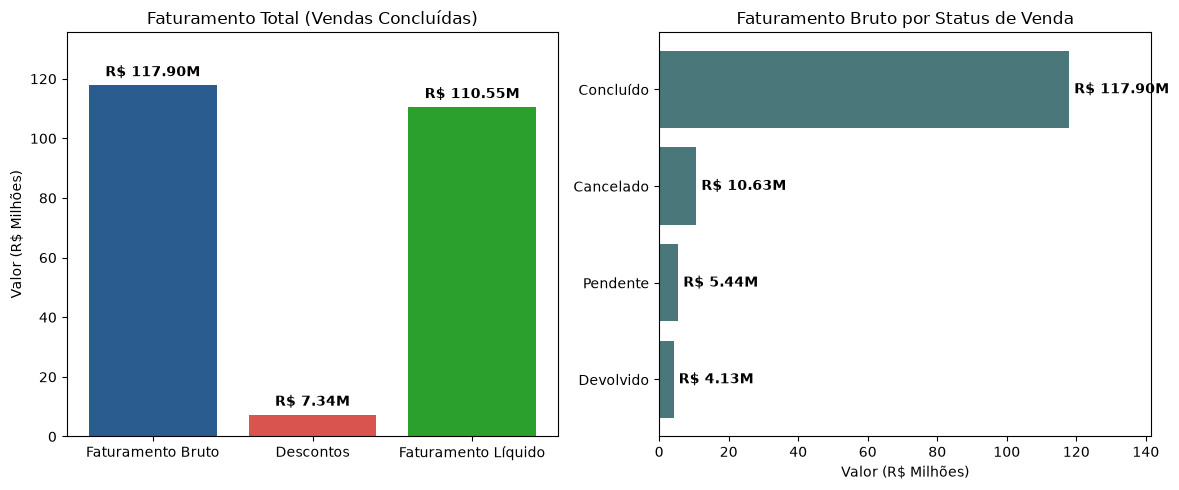

In [66]:
df_tratado['faturamento_bruto'] = df_tratado['quantidade'] * df_tratado['preco_unitario']

#filtro vendas concluídas
df_vendas_concluidas = df_tratado[df_tratado['status_venda'] == 'Concluído']
#calculando as categorias
faturamento_total_bruto = df_vendas_concluidas['faturamento_bruto'].sum()
total_descontos = df_vendas_concluidas['desconto'].sum()
faturamento_total_liquido = df_vendas_concluidas['valor_total'].sum()

#ver a media de descontos que estão aplicando nas vendas.
taxa_desconto = (total_descontos / faturamento_total_bruto) * 100

#exibindo os dados das vendas
print("-" * 13, "RESUMO DE FATURAMENTO (VENDAS CONCLUÍDAS)", "-" * 13)
print(f"Faturamento Total Bruto:   R$ {faturamento_total_bruto:,.2f}")
print(f"Total de Descontos:        R$ {total_descontos:,.2f} ({taxa_desconto:.2f}%)")
print(f"Faturamento Total Líquido: R$ {faturamento_total_liquido:,.2f}")

#inserindo em gráficos com subplots
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Gráfico 1: Comparativo Bruto vs. Líquido (em Milhões de R$)
categorias = ['Faturamento Bruto', 'Descontos', 'Faturamento Líquido']
valores_milhoes = [
    faturamento_total_bruto / 1000000,
    total_descontos / 1000000,
    faturamento_total_liquido / 1000000
]
cores = ['#2b5c8f', '#d9534f', '#2ca02c']

barras = axs[0].bar(categorias, valores_milhoes, color=cores)
axs[0].set_title('Faturamento Total (Vendas Concluídas)')
axs[0].set_ylabel('Valor (R$ Milhões)')
axs[0].set_ylim(0, max(valores_milhoes) * 1.15)

for barra in barras:
    altura = barra.get_height()
    axs[0].annotate(f'R$ {altura:.2f}M',
                    xy=(barra.get_x() + barra.get_width() / 2, altura),
                    xytext=(0, 4), textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold')

# Gráfico 2: Distribuição do Faturamento Bruto por Status de Venda
resumo_status = df_tratado.groupby('status_venda')['faturamento_bruto'].sum().sort_values(ascending=True)
axs[1].barh(resumo_status.index, resumo_status.values / 1e6, color='#4a777a')
axs[1].set_title('Faturamento Bruto por Status de Venda')
axs[1].set_xlabel('Valor (R$ Milhões)')
axs[1].set_xlim(0, (resumo_status.max() / 1e6) * 1.2)

for i, v in enumerate(resumo_status.values / 1e6):
    axs[1].text(v + 1.5, i, f'R$ {v:.2f}M', va='center', fontweight='bold')

plt.tight_layout()
plt.show()